# Phase 2: Returns and Performance

Uses the cleaned prices from Phase 1 to answer: **how did each IT stock perform, and did it beat the market (Nifty 50)?**

## 1. Import libraries

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

## 2. Load the cleaned data from Phase 1

`index_col="Date"` makes the date the row label, and `parse_dates=True` turns the text dates into real dates so pandas can do date maths with them.

In [2]:
prices = pd.read_csv("data/it_stocks_clean.csv", index_col="Date", parse_dates=True)

print("From:", prices.index[0].date(), "to", prices.index[-1].date())
prices.head()

From: 2023-10-09 to 2026-10-07


,TCS,Infosys,Wipro,HCLTech,Nifty 50
Date,,,,,
2023-10-09,3316.34,1342.32,187.56,1110.11,19512.35
2023-10-10,3307.72,1360.24,188.55,1120.95,19689.85
2023-10-11,3290.40,1359.56,194.75,1106.56,19811.35
2023-10-12,3229.01,1333.26,192.88,1087.15,19794.00
2023-10-13,3254.81,1302.01,190.08,1115.71,19751.05


## 3. Daily returns

A daily return is the percentage change in price from one trading day to the next:

$$\text{daily return} = \frac{\text{today's price}}{\text{yesterday's price}} - 1$$

Returns are better than prices for comparison: a ₹10 move means a lot for Wipro (~₹160) but very little for TCS (~₹2,000). A percentage puts them on the same scale.

The first day has no "yesterday", so its return is empty — `dropna()` removes it.

In [3]:
daily_returns = prices.pct_change().dropna()

daily_returns.head()

,TCS,Infosys,Wipro,HCLTech,Nifty 50
Date,,,,,
2023-10-10,-0.002599,0.013350,0.005278,0.009765,0.009097
2023-10-11,-0.005236,-0.000500,0.032883,-0.012837,0.006171
2023-10-12,-0.018657,-0.019344,-0.009602,-0.017541,-0.000876
2023-10-13,0.007990,-0.023439,-0.014517,0.026271,-0.002170
2023-10-16,-0.013107,0.002097,-0.002052,0.011741,-0.000977


In [4]:
# Average daily return and how much returns swing day to day (standard deviation)
daily_stats = pd.DataFrame({
    "Average daily return": daily_returns.mean(),
    "Daily std deviation": daily_returns.std(),
})

(daily_stats * 100).round(3).astype(str) + "%"

,Average daily return,Daily std deviation
TCS,-0.052%,1.493%
Infosys,-0.027%,1.665%
Wipro,-0.008%,1.683%
HCLTech,0.022%,1.647%
Nifty 50,0.023%,0.838%


## 4. Cumulative returns

Cumulative return is the total gain or loss from day one up to each date. Returns **compound**: a +10% day followed by a −10% day leaves you at 0.99, not 1.00. So instead of adding daily returns, we multiply the growth factors `(1 + daily return)` together with `cumprod()` (cumulative product).

In [5]:
cumulative_returns = (1 + daily_returns).cumprod() - 1

# Show the last 5 days as percentages
(cumulative_returns.tail() * 100).round(2)

,TCS,Infosys,Wipro,HCLTech,Nifty 50
Date,,,,,
2026-09-30,-38.17,-25.94,-15.49,10.80,15.93
2026-10-01,-37.43,-22.89,-15.04,11.98,14.91
2026-10-05,-36.24,-23.97,-13.55,8.27,15.60
2026-10-06,-36.68,-24.47,-13.71,8.49,16.73
2026-10-07,-37.27,-26.10,-14.91,6.75,15.84


In [6]:
# Cross-check: compounding daily returns must equal simply comparing
# the last price with the first price
simple_check = prices.iloc[-1] / prices.iloc[0] - 1
print((cumulative_returns.iloc[-1] - simple_check).abs().max() < 1e-9)

True


## 5. Performance chart, rebased to 100

Each series is divided by its own first price and multiplied by 100, so **everything starts at 100 on day one**. A value of 120 means +20%, and 80 means −20%. This lets us put a ₹160 stock and a 22,000-point index on one chart and compare them fairly.

The Nifty 50 is drawn as a thick dark line because it's the benchmark: a stock line above it is beating the market, and one below it is lagging.

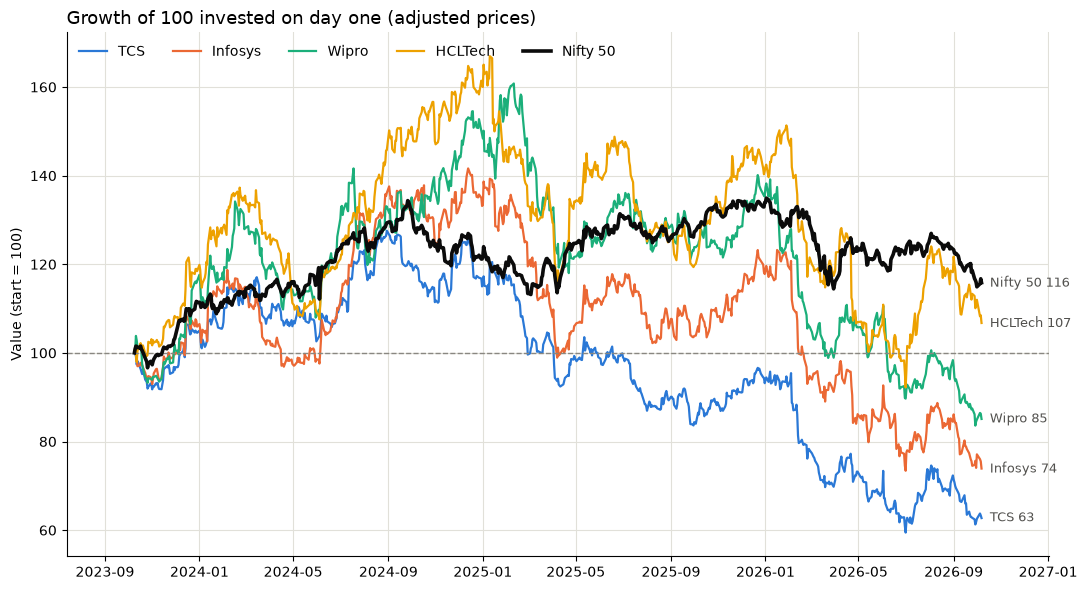

In [7]:
rebased = prices / prices.iloc[0] * 100

# One fixed colour per stock; the benchmark gets dark ink and a thicker line
colors = {
    "TCS": "#2a78d6",       # blue
    "Infosys": "#eb6834",   # orange
    "Wipro": "#1baf7a",     # green
    "HCLTech": "#eda100",   # yellow
    "Nifty 50": "#0b0b0b",  # near-black (benchmark)
}

fig, ax = plt.subplots(figsize=(11, 6))

for name in rebased.columns:
    is_benchmark = name == "Nifty 50"
    ax.plot(rebased.index, rebased[name], label=name, color=colors[name],
            linewidth=2.6 if is_benchmark else 1.6, zorder=3 if is_benchmark else 2)

    # Label the end of each line with its final value
    last_value = rebased[name].iloc[-1]
    ax.annotate(f"{name} {last_value:.0f}", xy=(rebased.index[-1], last_value),
                xytext=(6, 0), textcoords="offset points", va="center",
                fontsize=9, color="#52514e")

# Dashed line at 100 = break-even (no gain, no loss)
ax.axhline(100, color="#898781", linestyle="--", linewidth=1)

ax.set_title("Growth of 100 invested on day one (adjusted prices)", loc="left", fontsize=13)
ax.set_ylabel("Value (start = 100)")
ax.grid(color="#e1e0d9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", frameon=False, ncols=5)
ax.margins(x=0.08)  # leave room on the right for the end labels
fig.tight_layout()

os.makedirs("charts", exist_ok=True)
fig.savefig("charts/rebased_performance.png", dpi=150)
plt.show()

## 6. Total and annualised return

- **Total return**: the overall gain or loss across the whole period.
- **Annualised return (CAGR, Compound Annual Growth Rate)**: the steady yearly return that would turn the starting value into the ending value. It lets you compare investments held for different lengths of time, and compare against yearly figures like FD rates or inflation.

$$\text{CAGR} = (1 + \text{total return})^{1/\text{years}} - 1$$

- **vs Nifty**: the difference from the benchmark's return, in percentage points. Negative means the stock did worse than simply holding the market.

In [8]:
# Length of the period in years (365.25 days per year allows for leap years)
years = (prices.index[-1] - prices.index[0]).days / 365.25
print(f"Period: {years:.2f} years")

total_return = prices.iloc[-1] / prices.iloc[0] - 1
annualised_return = (1 + total_return) ** (1 / years) - 1

summary = pd.DataFrame({
    "Total return": total_return,
    "Annualised return (CAGR)": annualised_return,
})

# Difference from the Nifty 50, in percentage points
summary["Total vs Nifty"] = summary["Total return"] - summary.loc["Nifty 50", "Total return"]
summary["CAGR vs Nifty"] = (summary["Annualised return (CAGR)"]
                            - summary.loc["Nifty 50", "Annualised return (CAGR)"])

summary = summary.sort_values("Total return", ascending=False)  # best first

# Show as percentages with 1 decimal place
(summary * 100).round(1).astype(str) + "%"

Period: 3.00 years


,Total return,Annualised return (CAGR),Total vs Nifty,CAGR vs Nifty
Nifty 50,15.8%,5.0%,0.0%,0.0%
HCLTech,6.7%,2.2%,-9.1%,-2.8%
Wipro,-14.9%,-5.2%,-30.7%,-10.3%
Infosys,-26.1%,-9.6%,-41.9%,-14.6%
TCS,-37.3%,-14.4%,-53.1%,-19.4%


## 7. What would ₹10,000 have become?

Same calculation, in rupees: ₹10,000 × (last price ÷ first price).

**Assumptions:** adjusted prices include dividends, so this assumes dividends were reinvested. It ignores brokerage, taxes and other costs, and you can't buy the Nifty itself — in practice you'd use a Nifty 50 index fund or ETF, which has small fees.

In [9]:
INVESTMENT = 10_000  # rupees

investment = pd.DataFrame({
    "Invested (₹)": INVESTMENT,
    "Value today (₹)": INVESTMENT * (1 + summary["Total return"]),
})
investment["Profit / loss (₹)"] = investment["Value today (₹)"] - investment["Invested (₹)"]

investment.round(0).astype(int)

,Invested (₹),Value today (₹),Profit / loss (₹)
Nifty 50,10000,11584,1584
HCLTech,10000,10675,675
Wipro,10000,8509,-1491
Infosys,10000,7390,-2610
TCS,10000,6273,-3727


## 8. Save the summary

Saved as plain numbers (0.05 = 5%) so later phases can reuse them.

In [10]:
output = summary.join(investment[["Value today (₹)"]])
output.round(4).to_csv("data/performance_summary.csv", encoding="utf-8-sig")
print("Saved data/performance_summary.csv")

Saved data/performance_summary.csv
